# Task 1.4 — Two ML Models with Scikit-learn
**Week 1 · AI/ML Internship (Skill Set Go EduTech)** · Author: Neela Vyshali

**Objective.** Build and evaluate **one regression model and one classification model**, including preprocessing, a train/test split and evaluation metrics.

**Deliverable.** This notebook with two trained models and an evaluation report (Part C).

| Part | Problem | Dataset | Main model | Comparison model |
|---|---|---|---|---|
| A | **Regression** — predict a car's fuel efficiency (mpg) | Auto MPG (398 cars) | Linear Regression | Random Forest Regressor |
| B | **Classification** — predict whether a passenger survived | Titanic (891 passengers) | Logistic Regression | Random Forest Classifier |
| C | Evaluation report comparing everything | — | — | — |

**Method used for both parts:** load → inspect → train/test split (80/20, fixed seed) → preprocessing **inside a scikit-learn `Pipeline`** (so imputers/scalers are fitted on training data only, which prevents data leakage) → train → cross-validate → evaluate on the untouched test set → interpret.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)

RANDOM_STATE = 42
pd.set_option("display.width", 120); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

---
# Part A — Regression: predicting fuel efficiency (mpg)
**Problem.** Given a car's engine and body characteristics, predict its fuel consumption in miles per gallon (a *continuous* target).

### A1. Load and inspect the data

In [2]:
MPG_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
mpg = pd.read_csv(MPG_URL)
print("shape:", mpg.shape)
print("missing values:", mpg.isna().sum()[mpg.isna().sum() > 0].to_dict())
display(mpg.head())
display(mpg.describe().round(2))

shape: (398, 9)
missing values: {'horsepower': 6}


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.00,398.00,398.00,392.00,398.00,398.00,398.00
mean,23.51,5.45,193.43,104.47,2970.42,15.57,76.01
std,7.82,1.70,104.27,38.49,846.84,2.76,3.70
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.50,4.00,104.25,75.00,2223.75,13.82,73.00
50%,23.00,4.00,148.50,93.50,2803.50,15.50,76.00
75%,29.00,8.00,262.00,126.00,3608.00,17.18,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


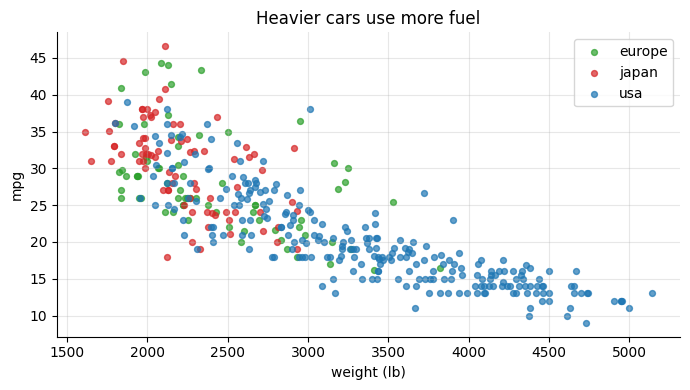

In [3]:
colors = {"usa": "C0", "japan": "C3", "europe": "C2"}
for origin, g in mpg.groupby("origin"):
    plt.scatter(g["weight"], g["mpg"], s=18, alpha=0.7, label=origin, color=colors[origin])
plt.xlabel("weight (lb)"); plt.ylabel("mpg"); plt.title("Heavier cars use more fuel"); plt.legend()
plt.tight_layout(); plt.show()

The relationship is clearly negative and slightly curved. `horsepower` has a few missing values, which the pipeline will impute.

### A2. Features, target and train/test split

In [4]:
num_cols = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
cat_cols = ["origin"]
X, y = mpg[num_cols + cat_cols], mpg["mpg"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"train: {X_train.shape[0]} rows | test: {X_test.shape[0]} rows")

train: 318 rows | test: 80 rows


### A3. Preprocessing
- Numeric columns: fill missing values with the **median**, then **standardise** (mean 0, std 1) — needed for comparable coefficients in linear models.
- Categorical column `origin`: **one-hot encode** (unknown categories ignored).

In [5]:
pre_reg = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
reg_models = {
    "Linear Regression": Pipeline([("prep", clone(pre_reg)), ("model", LinearRegression())]),
    "Random Forest":     Pipeline([("prep", clone(pre_reg)), ("model", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE))]),
}

### A4. Train and evaluate

In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_rows = {}
for name, model in reg_models.items():
    cv_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2")       # CV on training data only
    model.fit(X_train, y_train)
    pred_tr, pred_te = model.predict(X_train), model.predict(X_test)
    reg_rows[name] = {"train R²": r2_score(y_train, pred_tr), "CV R² (5-fold)": cv_r2.mean(),
                      "test R²": r2_score(y_test, pred_te), "test MAE": mean_absolute_error(y_test, pred_te),
                      "test RMSE": np.sqrt(mean_squared_error(y_test, pred_te))}

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)               # "always predict the average"
pb = baseline.predict(X_test)
reg_rows["Baseline (predict mean)"] = {"train R²": 0.0, "CV R² (5-fold)": np.nan, "test R²": r2_score(y_test, pb),
                                       "test MAE": mean_absolute_error(y_test, pb),
                                       "test RMSE": np.sqrt(mean_squared_error(y_test, pb))}
reg_table = pd.DataFrame(reg_rows).T.round(3)
reg_table

,train R²,CV R² (5-fold),test R²,test MAE,test RMSE
Linear Regression,0.819,0.803,0.845,2.288,2.888
Random Forest,0.981,0.853,0.912,1.595,2.172
Baseline (predict mean),0.000,NaN,-0.004,5.955,7.347


**Metrics explained.** **R²** = share of the variance in mpg the model explains (1 = perfect, 0 = no better than predicting the mean). **MAE** = average absolute error in mpg. **RMSE** = like MAE but penalises large errors more. A big gap between *train* and *test* R² signals overfitting.

### A5. Visual evaluation

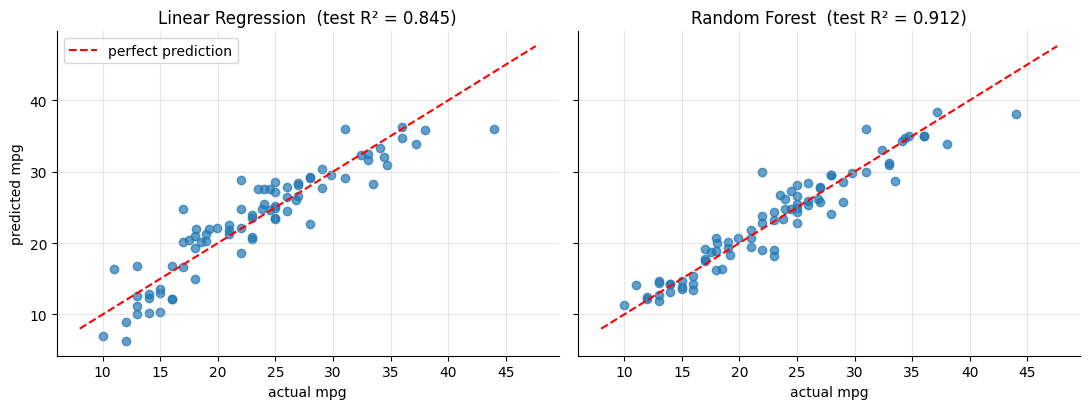

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
lims = [y.min() - 1, y.max() + 1]
for a, (name, model) in zip(ax, reg_models.items()):
    pred = model.predict(X_test)
    a.scatter(y_test, pred, alpha=0.7)
    a.plot(lims, lims, "r--", label="perfect prediction")
    a.set_title(f"{name}  (test R² = {r2_score(y_test, pred):.3f})"); a.set_xlabel("actual mpg")
ax[0].set_ylabel("predicted mpg"); ax[0].legend(); plt.tight_layout(); plt.show()

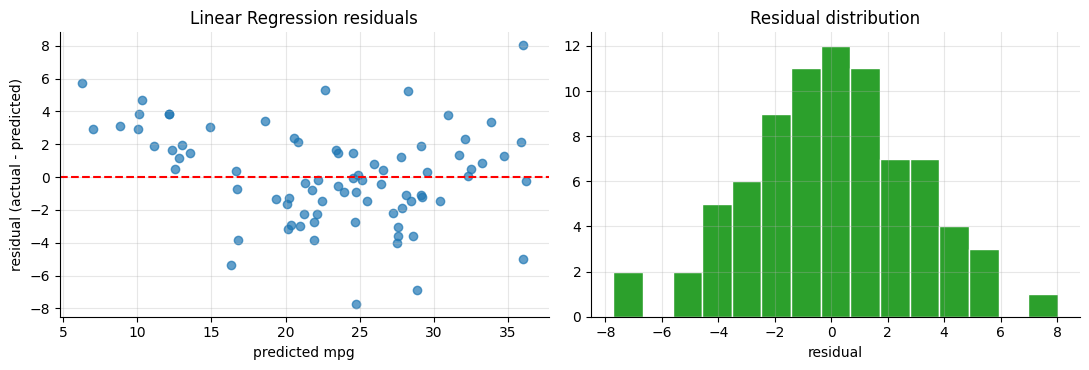

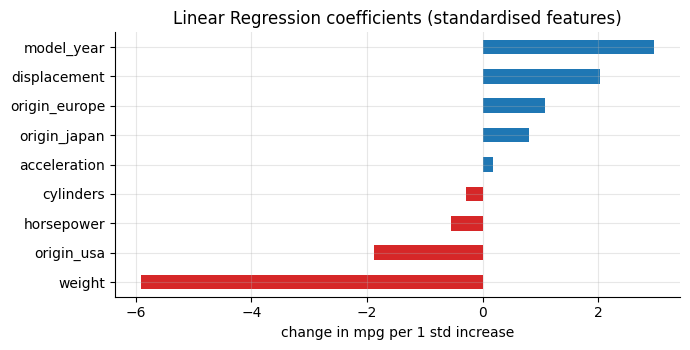

In [8]:
lin = reg_models["Linear Regression"]
res = y_test - lin.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(lin.predict(X_test), res, alpha=0.7); ax[0].axhline(0, color="r", ls="--")
ax[0].set_xlabel("predicted mpg"); ax[0].set_ylabel("residual (actual - predicted)"); ax[0].set_title("Linear Regression residuals")
ax[1].hist(res, bins=15, color="C2", edgecolor="white"); ax[1].set_title("Residual distribution"); ax[1].set_xlabel("residual")
plt.tight_layout(); plt.show()

names = lin.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lin.named_steps["model"].coef_, index=[n.split("__")[1] for n in names]).sort_values()
ax = coefs.plot.barh(color=["C3" if c < 0 else "C0" for c in coefs], figsize=(7, 3.6))
ax.set_title("Linear Regression coefficients (standardised features)"); ax.set_xlabel("change in mpg per 1 std increase")
plt.tight_layout(); plt.show()

**Reading the plots.** Points close to the red dashed line are good predictions. In the residual plot the errors are centred on zero, but they curve slightly upward at both the low and high ends — a hint that the relationship is not perfectly linear, which is why the non-linear Random Forest does better. The largest coefficient is `weight` (negative: heavier cars use more fuel), followed by `model_year` (positive: newer cars are more efficient).

**Careful with coefficients:** `displacement` gets a *positive* sign even though bigger engines burn more fuel. This happens because `displacement`, `cylinders`, `horsepower` and `weight` are strongly correlated with one another (multicollinearity), so individual coefficients should not be read as separate cause-and-effect effects.

---
# Part B — Classification: predicting Titanic survival
**Problem.** Given a passenger's class, sex, age, family aboard, fare and port, predict whether they survived (**1 = survived, 0 = died**).

### B1. Load and inspect the data

In [9]:
TITANIC_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(TITANIC_URL)
print("shape:", titanic.shape)
print("class balance (Survived):", titanic["Survived"].value_counts(normalize=True).round(3).to_dict())
print("missing values:", titanic[["Age", "SibSp", "Parch", "Fare", "Pclass", "Sex", "Embarked"]].isna().sum().to_dict())

shape: (891, 12)
class balance (Survived): {0: 0.616, 1: 0.384}
missing values: {'Age': 177, 'SibSp': 0, 'Parch': 0, 'Fare': 0, 'Pclass': 0, 'Sex': 0, 'Embarked': 2}


The classes are moderately imbalanced (about 62% died), so **accuracy alone is not enough** — precision, recall, F1 and ROC-AUC are also reported.

### B2. Features, target and stratified train/test split

In [10]:
features_num = ["Age", "SibSp", "Parch", "Fare"]
features_cat = ["Pclass", "Sex", "Embarked"]        # Pclass is treated as a category (1st/2nd/3rd)
Xc, yc = titanic[features_num + features_cat], titanic["Survived"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=RANDOM_STATE, stratify=yc)      # stratify keeps the class ratio equal
print(f"train: {len(Xc_train)} rows | test: {len(Xc_test)} rows")
print("survival rate  train:", round(yc_train.mean(), 3), "| test:", round(yc_test.mean(), 3))

train: 712 rows | test: 179 rows
survival rate  train: 0.383 | test: 0.385


### B3. Preprocessing
- Numeric: median imputation (fixes the missing `Age`) + standardisation.
- Categorical: most-frequent imputation (fixes missing `Embarked`) + one-hot encoding.

In [11]:
pre_clf = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), features_num),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), features_cat),
])
clf_models = {
    "Logistic Regression": Pipeline([("prep", clone(pre_clf)), ("model", LogisticRegression(max_iter=1000))]),
    "Random Forest":       Pipeline([("prep", clone(pre_clf)), ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))]),
}

### B4. Train and evaluate

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
clf_rows = {}
def clf_row(model, cv_acc=np.nan):
    pred, proba = model.predict(Xc_test), model.predict_proba(Xc_test)[:, 1]
    return {"train acc": accuracy_score(yc_train, model.predict(Xc_train)), "CV acc (5-fold)": cv_acc,
            "test acc": accuracy_score(yc_test, pred), "precision": precision_score(yc_test, pred),
            "recall": recall_score(yc_test, pred), "F1": f1_score(yc_test, pred), "ROC-AUC": roc_auc_score(yc_test, proba)}

for name, model in clf_models.items():
    cv_acc = cross_val_score(model, Xc_train, yc_train, cv=skf, scoring="accuracy").mean()
    model.fit(Xc_train, yc_train)
    clf_rows[name] = clf_row(model, cv_acc)

dummy = DummyClassifier(strategy="most_frequent").fit(Xc_train, yc_train)       # "always predict died"
clf_rows["Baseline (majority class)"] = {"train acc": accuracy_score(yc_train, dummy.predict(Xc_train)), "CV acc (5-fold)": np.nan,
    "test acc": accuracy_score(yc_test, dummy.predict(Xc_test)), "precision": 0.0, "recall": 0.0, "F1": 0.0, "ROC-AUC": 0.5}
clf_table = pd.DataFrame(clf_rows).T.round(3)
clf_table

,train acc,CV acc (5-fold),test acc,precision,recall,F1,ROC-AUC
Logistic Regression,0.810,0.802,0.804,0.793,0.667,0.724,0.843
Random Forest,0.983,0.799,0.816,0.810,0.681,0.740,0.832
Baseline (majority class),0.617,NaN,0.615,0.000,0.000,0.000,0.500


**Metrics explained.** **Accuracy** = share of correct predictions. **Precision** = of those predicted "survived", how many really survived. **Recall** = of the real survivors, how many were found. **F1** = harmonic mean of precision and recall. **ROC-AUC** = ability to rank survivors above non-survivors (0.5 = random, 1 = perfect).

In [13]:
lr = clf_models["Logistic Regression"]
print(classification_report(yc_test, lr.predict(Xc_test), target_names=["Died", "Survived"], digits=3))

              precision    recall  f1-score   support

        Died      0.810     0.891     0.848       110
    Survived      0.793     0.667     0.724        69

    accuracy                          0.804       179
   macro avg      0.802     0.779     0.786       179
weighted avg      0.803     0.804     0.801       179



### B5. Visual evaluation

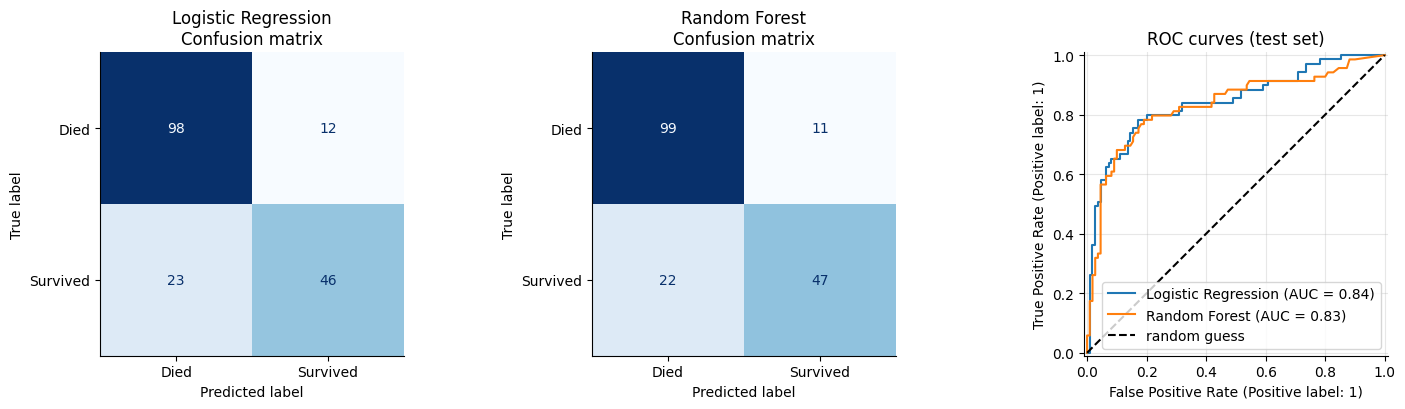

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (name, model) in zip(ax[:2], clf_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, Xc_test, yc_test, display_labels=["Died", "Survived"],
                                          ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{name}\nConfusion matrix"); a.grid(False)
for name, model in clf_models.items():
    RocCurveDisplay.from_estimator(model, Xc_test, yc_test, ax=ax[2], name=name)
ax[2].plot([0, 1], [0, 1], "k--", label="random guess"); ax[2].set_title("ROC curves (test set)"); ax[2].legend()
plt.tight_layout(); plt.show()

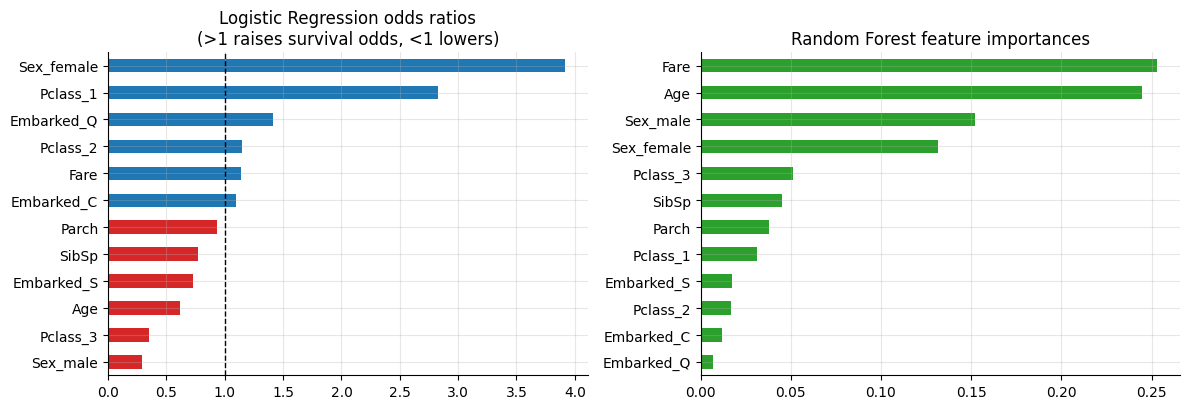

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
lr_names = [n.split("__")[1] for n in lr.named_steps["prep"].get_feature_names_out()]
odds = pd.Series(np.exp(lr.named_steps["model"].coef_[0]), index=lr_names).sort_values()
odds.plot.barh(ax=ax[0], color=["C3" if o < 1 else "C0" for o in odds])
ax[0].axvline(1, color="k", ls="--", lw=1); ax[0].set_title("Logistic Regression odds ratios\n(>1 raises survival odds, <1 lowers)")

rf = clf_models["Random Forest"]
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=lr_names).sort_values()
imp.plot.barh(ax=ax[1], color="C2"); ax[1].set_title("Random Forest feature importances")
plt.tight_layout(); plt.show()

---
# Part C — Evaluation Report

In [16]:
reg_names, clf_names = list(reg_models), list(clf_models)
best_reg = reg_table.loc[reg_names, "test R²"].idxmax()
best_clf = clf_table.loc[clf_names, "test acc"].idxmax()
best_auc = clf_table.loc[clf_names, "ROC-AUC"].idxmax()
gap = lambda t, n, tr, te: t.loc[n, tr] - t.loc[n, te]

lin_r, rf_r = reg_table.loc["Linear Regression"], reg_table.loc["Random Forest"]
lr_r, rfc_r = clf_table.loc["Logistic Regression"], clf_table.loc["Random Forest"]
base_r, base_c = reg_table.loc["Baseline (predict mean)"], clf_table.loc["Baseline (majority class)"]

rank_same = (lin_r["CV R² (5-fold)"] < rf_r["CV R² (5-fold)"]) == (lin_r["test R²"] < rf_r["test R²"])
rank_note = "Cross-validation and the test set rank the two models the same way." if rank_same else "Cross-validation and the test set disagree on the ranking, so the models are close."
top_lr = ", ".join(odds.abs().index[:0]) or ", ".join(pd.Series(np.log(odds)).abs().sort_values(ascending=False).index[:3])
top_rf = ", ".join(imp.sort_values(ascending=False).index[:3])

display(Markdown("### Regression results (Auto MPG, test set)"))
display(reg_table)
display(Markdown("### Classification results (Titanic, test set)"))
display(clf_table)

display(Markdown(f'''
## Findings

**Regression — predicting mpg**
- The best model on unseen data is **{best_reg}** (test R² = {reg_table.loc[best_reg, "test R²"]:.3f}, MAE = {reg_table.loc[best_reg, "test MAE"]:.2f} mpg, RMSE = {reg_table.loc[best_reg, "test RMSE"]:.2f} mpg).
- Both models beat the "predict the average" baseline by a wide margin (baseline MAE = {base_r["test MAE"]:.2f} mpg, R² ≈ 0).
- Linear Regression explains {lin_r["test R²"]:.1%} of the variance on the test set; Random Forest explains {rf_r["test R²"]:.1%}.
- **Overfitting check:** train-minus-test R² is {gap(reg_table, "Linear Regression", "train R²", "test R²"):.3f} for Linear Regression and {gap(reg_table, "Random Forest", "train R²", "test R²"):.3f} for Random Forest. A gap close to zero (or slightly negative, meaning this test split happened to be a little easier than the training data) shows no overfitting; a larger gap for the forest is expected because it fits the training data very closely.
- Cross-validated R² on the training data is {lin_r["CV R² (5-fold)"]:.3f} (linear) and {rf_r["CV R² (5-fold)"]:.3f} (forest): the more conservative estimate. {rank_note}

**Classification — predicting survival**
- The best test accuracy is **{best_clf}** ({clf_table.loc[best_clf, "test acc"]:.1%}); the best ROC-AUC is **{best_auc}** ({clf_table.loc[best_auc, "ROC-AUC"]:.3f}).
- The majority-class baseline reaches {base_c["test acc"]:.1%}, so the models add about {(clf_table.loc[best_clf, "test acc"] - base_c["test acc"]) * 100:.0f} percentage points of accuracy.
- Logistic Regression: precision {lr_r["precision"]:.2f}, recall {lr_r["recall"]:.2f}, F1 {lr_r["F1"]:.2f}. Random Forest: precision {rfc_r["precision"]:.2f}, recall {rfc_r["recall"]:.2f}, F1 {rfc_r["F1"]:.2f}.
- **Overfitting check:** train-minus-test accuracy is {gap(clf_table, "Logistic Regression", "train acc", "test acc"):.3f} (Logistic) vs {gap(clf_table, "Random Forest", "train acc", "test acc"):.3f} (Random Forest). The forest memorises the training set, so its large gap signals overfitting; limiting `max_depth` or raising `min_samples_leaf` is the next step.
- Most influential features — Logistic Regression (largest effect): {top_lr}; Random Forest (importance): {top_rf}. In Task 1.2 sex and class showed the strongest relationship with survival, and the logistic model confirms that (women and 1st class raise the odds; men and 3rd class lower them). The forest ranks the continuous columns `Fare` and `Age` highly partly because continuous features offer many split points.

## Why the results can be trusted
- Imputation, scaling and encoding live **inside the Pipeline**, so they are learned from training data only (no data leakage).
- Fixed `random_state = 42`, so the results are reproducible; the Titanic split is **stratified**.
- Cross-validation was run on the training set only; the **test set was used once** for the final numbers.
- Every model is compared with a naive baseline, so scores are meaningful.

## Limitations and next steps
- One random split on small datasets: the exact numbers would move a little with another seed (cross-validation gives a more stable estimate than a single split).
- No hyper-parameter tuning yet: next step is `GridSearchCV` / `RandomizedSearchCV` (e.g., forest depth, regularisation strength `C`).
- Titanic: reuse the engineered features from Task 1.2 (`title`, `family_size`, `has_cabin`) and tune the decision threshold if recall on survivors matters more than precision.
- Auto MPG: try non-linear terms (e.g., `weight²`) or Gradient Boosting; check residuals by origin for bias.
'''))

### Regression results (Auto MPG, test set)

,train R²,CV R² (5-fold),test R²,test MAE,test RMSE
Linear Regression,0.819,0.803,0.845,2.288,2.888
Random Forest,0.981,0.853,0.912,1.595,2.172
Baseline (predict mean),0.000,NaN,-0.004,5.955,7.347


### Classification results (Titanic, test set)

,train acc,CV acc (5-fold),test acc,precision,recall,F1,ROC-AUC
Logistic Regression,0.810,0.802,0.804,0.793,0.667,0.724,0.843
Random Forest,0.983,0.799,0.816,0.810,0.681,0.740,0.832
Baseline (majority class),0.617,NaN,0.615,0.000,0.000,0.000,0.500



## Findings

**Regression — predicting mpg**
- The best model on unseen data is **Random Forest** (test R² = 0.912, MAE = 1.59 mpg, RMSE = 2.17 mpg).
- Both models beat the "predict the average" baseline by a wide margin (baseline MAE = 5.96 mpg, R² ≈ 0).
- Linear Regression explains 84.5% of the variance on the test set; Random Forest explains 91.2%.
- **Overfitting check:** train-minus-test R² is -0.026 for Linear Regression and 0.069 for Random Forest. A gap close to zero (or slightly negative, meaning this test split happened to be a little easier than the training data) shows no overfitting; a larger gap for the forest is expected because it fits the training data very closely.
- Cross-validated R² on the training data is 0.803 (linear) and 0.853 (forest): the more conservative estimate. Cross-validation and the test set rank the two models the same way.

**Classification — predicting survival**
- The best test accuracy is **Random Forest** (81.6%); the best ROC-AUC is **Logistic Regression** (0.843).
- The majority-class baseline reaches 61.5%, so the models add about 20 percentage points of accuracy.
- Logistic Regression: precision 0.79, recall 0.67, F1 0.72. Random Forest: precision 0.81, recall 0.68, F1 0.74.
- **Overfitting check:** train-minus-test accuracy is 0.006 (Logistic) vs 0.167 (Random Forest). The forest memorises the training set, so its large gap signals overfitting; limiting `max_depth` or raising `min_samples_leaf` is the next step.
- Most influential features — Logistic Regression (largest effect): Sex_female, Sex_male, Pclass_3; Random Forest (importance): Fare, Age, Sex_male. In Task 1.2 sex and class showed the strongest relationship with survival, and the logistic model confirms that (women and 1st class raise the odds; men and 3rd class lower them). The forest ranks the continuous columns `Fare` and `Age` highly partly because continuous features offer many split points.

## Why the results can be trusted
- Imputation, scaling and encoding live **inside the Pipeline**, so they are learned from training data only (no data leakage).
- Fixed `random_state = 42`, so the results are reproducible; the Titanic split is **stratified**.
- Cross-validation was run on the training set only; the **test set was used once** for the final numbers.
- Every model is compared with a naive baseline, so scores are meaningful.

## Limitations and next steps
- One random split on small datasets: the exact numbers would move a little with another seed (cross-validation gives a more stable estimate than a single split).
- No hyper-parameter tuning yet: next step is `GridSearchCV` / `RandomizedSearchCV` (e.g., forest depth, regularisation strength `C`).
- Titanic: reuse the engineered features from Task 1.2 (`title`, `family_size`, `has_cabin`) and tune the decision threshold if recall on survivors matters more than precision.
- Auto MPG: try non-linear terms (e.g., `weight²`) or Gradient Boosting; check residuals by origin for bias.
